In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from feature_engine.outliers import Winsorizer
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans

import joblib
import warnings
warnings.filterwarnings("ignore")

In [99]:
dataset = pd.read_csv("customer_segmentation.csv")
dataset.head()

,customer_id,age,gender,city,annual_income,monthly_income,membership_type,tenure_months,total_orders,purchase_frequency_monthly,...,complaint_level,loyalty_points,loyalty_status,email_open_rate,ad_click_rate,payment_method,device_type,marketing_channel,review_rating,cluster_label_hint
0,SEG000001,26,Male,Nagpur,441099.0,36758.25,Gold,11,33,3.08,...,NaN,431,Low,0.29,0.21,Net Banking,Desktop,Offline,3.2,Budget Conscious
1,SEG000002,51,Male,Chennai,469034.0,39086.17,Gold,44,47,1.27,...,NaN,528,Low,0.18,0.14,UPI,Mobile,Email,2.8,At Risk
2,SEG000003,30,Male,Mumbai,1056803.0,88066.92,Silver,49,361,7.37,...,Low,6600,High,0.75,0.17,Net Banking,Tablet,Organic Search,3.7,Loyal Regular
3,SEG000004,32,Female,Kolkata,397014.0,33084.50,Platinum,41,46,1.32,...,Low,1005,Medium,0.43,0.07,Credit Card,Tablet,Referral,3.1,Occasional Buyer
4,SEG000005,54,Female,Bengaluru,639236.0,53269.67,Silver,63,686,10.86,...,NaN,20167,High,0.50,0.28,Net Banking,Mobile,Google Ads,4.1,High Value


In [100]:
dataset.shape

(100000, 32)

In [101]:
dataset.tail()

,customer_id,age,gender,city,annual_income,monthly_income,membership_type,tenure_months,total_orders,purchase_frequency_monthly,...,complaint_level,loyalty_points,loyalty_status,email_open_rate,ad_click_rate,payment_method,device_type,marketing_channel,review_rating,cluster_label_hint
99995,SEG099996,37,Male,Ahmedabad,184607.0,15383.92,Platinum,25,68,2.93,...,NaN,1132,Medium,0.50,0.11,UPI,Desktop,Offline,4.2,Loyal Regular
99996,SEG099997,31,Female,Nagpur,565515.0,47126.25,Gold,56,438,7.78,...,Low,5293,High,0.36,0.19,Cash on Delivery,Tablet,Google Ads,3.9,Loyal Regular
99997,SEG099998,30,Male,Kolkata,827696.0,68974.67,Silver,29,136,5.23,...,NaN,2233,Medium,0.19,0.24,Cash on Delivery,Tablet,Organic Search,3.9,Loyal Regular
99998,SEG099999,18,Male,Delhi,834209.0,69517.42,Silver,6,22,2.10,...,Low,290,Low,0.00,0.07,Net Banking,Mobile,Offline,4.7,Occasional Buyer
99999,SEG100000,36,Male,Nagpur,467230.0,38935.83,Silver,3,25,6.13,...,Low,12,Low,0.19,0.37,Credit Card,Mobile,Offline,4.0,Budget Conscious


In [102]:
dataset.isnull().sum()

customer_id                       0
age                               0
gender                            0
city                              0
annual_income                     0
monthly_income                    0
membership_type                   0
tenure_months                     0
total_orders                      0
purchase_frequency_monthly        0
average_order_value               0
total_spend                       0
discount_usage_rate               0
coupon_usage_count                0
website_visits_monthly            0
app_usage_hours_weekly            0
cart_abandonment_rate             0
days_since_last_purchase          0
preferred_category                0
num_categories_purchased          0
return_rate                       0
customer_support_calls            0
complaint_level               50000
loyalty_points                    0
loyalty_status                    0
email_open_rate                   0
ad_click_rate                     0
payment_method              

In [103]:
# x = dataset.iloc[:, :-1]
x = dataset.drop(["customer_id", "cluster_label_hint"], axis=1)
y = dataset.iloc[:, -1]

In [104]:
x.head()

,age,gender,city,annual_income,monthly_income,membership_type,tenure_months,total_orders,purchase_frequency_monthly,average_order_value,...,customer_support_calls,complaint_level,loyalty_points,loyalty_status,email_open_rate,ad_click_rate,payment_method,device_type,marketing_channel,review_rating
0,26,Male,Nagpur,441099.0,36758.25,Gold,11,33,3.08,822.39,...,1,NaN,431,Low,0.29,0.21,Net Banking,Desktop,Offline,3.2
1,51,Male,Chennai,469034.0,39086.17,Gold,44,47,1.27,748.68,...,6,NaN,528,Low,0.18,0.14,UPI,Mobile,Email,2.8
2,30,Male,Mumbai,1056803.0,88066.92,Silver,49,361,7.37,2287.03,...,2,Low,6600,High,0.75,0.17,Net Banking,Tablet,Organic Search,3.7
3,32,Female,Kolkata,397014.0,33084.50,Platinum,41,46,1.32,1501.70,...,1,Low,1005,Medium,0.43,0.07,Credit Card,Tablet,Referral,3.1
4,54,Female,Bengaluru,639236.0,53269.67,Silver,63,686,10.86,3549.02,...,0,NaN,20167,High,0.50,0.28,Net Banking,Mobile,Google Ads,4.1


In [105]:
y.head()

0    Budget Conscious
1             At Risk
2       Loyal Regular
3    Occasional Buyer
4          High Value
Name: cluster_label_hint, dtype: object

In [106]:
numeric_feature = x.select_dtypes(exclude=["object"]).columns
catag_feature = x.select_dtypes(include=["object"]).columns

In [107]:
numeric_feature

Index(['age', 'annual_income', 'monthly_income', 'tenure_months',
       'total_orders', 'purchase_frequency_monthly', 'average_order_value',
       'total_spend', 'discount_usage_rate', 'coupon_usage_count',
       'website_visits_monthly', 'app_usage_hours_weekly',
       'cart_abandonment_rate', 'days_since_last_purchase',
       'num_categories_purchased', 'return_rate', 'customer_support_calls',
       'loyalty_points', 'email_open_rate', 'ad_click_rate', 'review_rating'],
      dtype='object')

In [108]:
catag_feature

Index(['gender', 'city', 'membership_type', 'preferred_category',
       'complaint_level', 'loyalty_status', 'payment_method', 'device_type',
       'marketing_channel'],
      dtype='object')

In [109]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("winsorizer", Winsorizer(capping_method="iqr", tail="both", fold=1.5)),
    ("scaler", MinMaxScaler())
])

In [110]:
catag_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

In [111]:
preprocess_pipeline = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_feature),
    ("catag", catag_pipeline, catag_feature)
])

In [112]:
clean = preprocess_pipeline.fit(x)

In [113]:
Clean_data = pd.DataFrame(clean.transform(x))

In [114]:
Clean_data.head()

,0,1,2,3,4,5,6,7,8,9,...,46,47,48,49,50,51,52,53,54,55
0,0.16,0.185546,0.185546,0.120482,0.054503,0.230472,0.174511,0.014488,0.588235,0.149378,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.66,0.205398,0.205398,0.518072,0.078348,0.090487,0.153843,0.031491,0.104575,0.024896,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.24,0.623088,0.623088,0.578313,0.613157,0.562258,0.585179,0.587323,0.352941,0.821577,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,0.28,0.154218,0.154218,0.481928,0.076645,0.094354,0.364981,0.057165,0.196078,0.091286,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.72,0.326350,0.326350,0.746988,1.000000,0.832173,0.939026,1.000000,0.248366,1.000000,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [115]:
joblib.dump(clean, "kmeans_preprocess_pipeline.pkl")

['kmeans_preprocess_pipeline.pkl']

In [116]:
joblib.load("kmeans_preprocess_pipeline.pkl")

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('catag', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. 

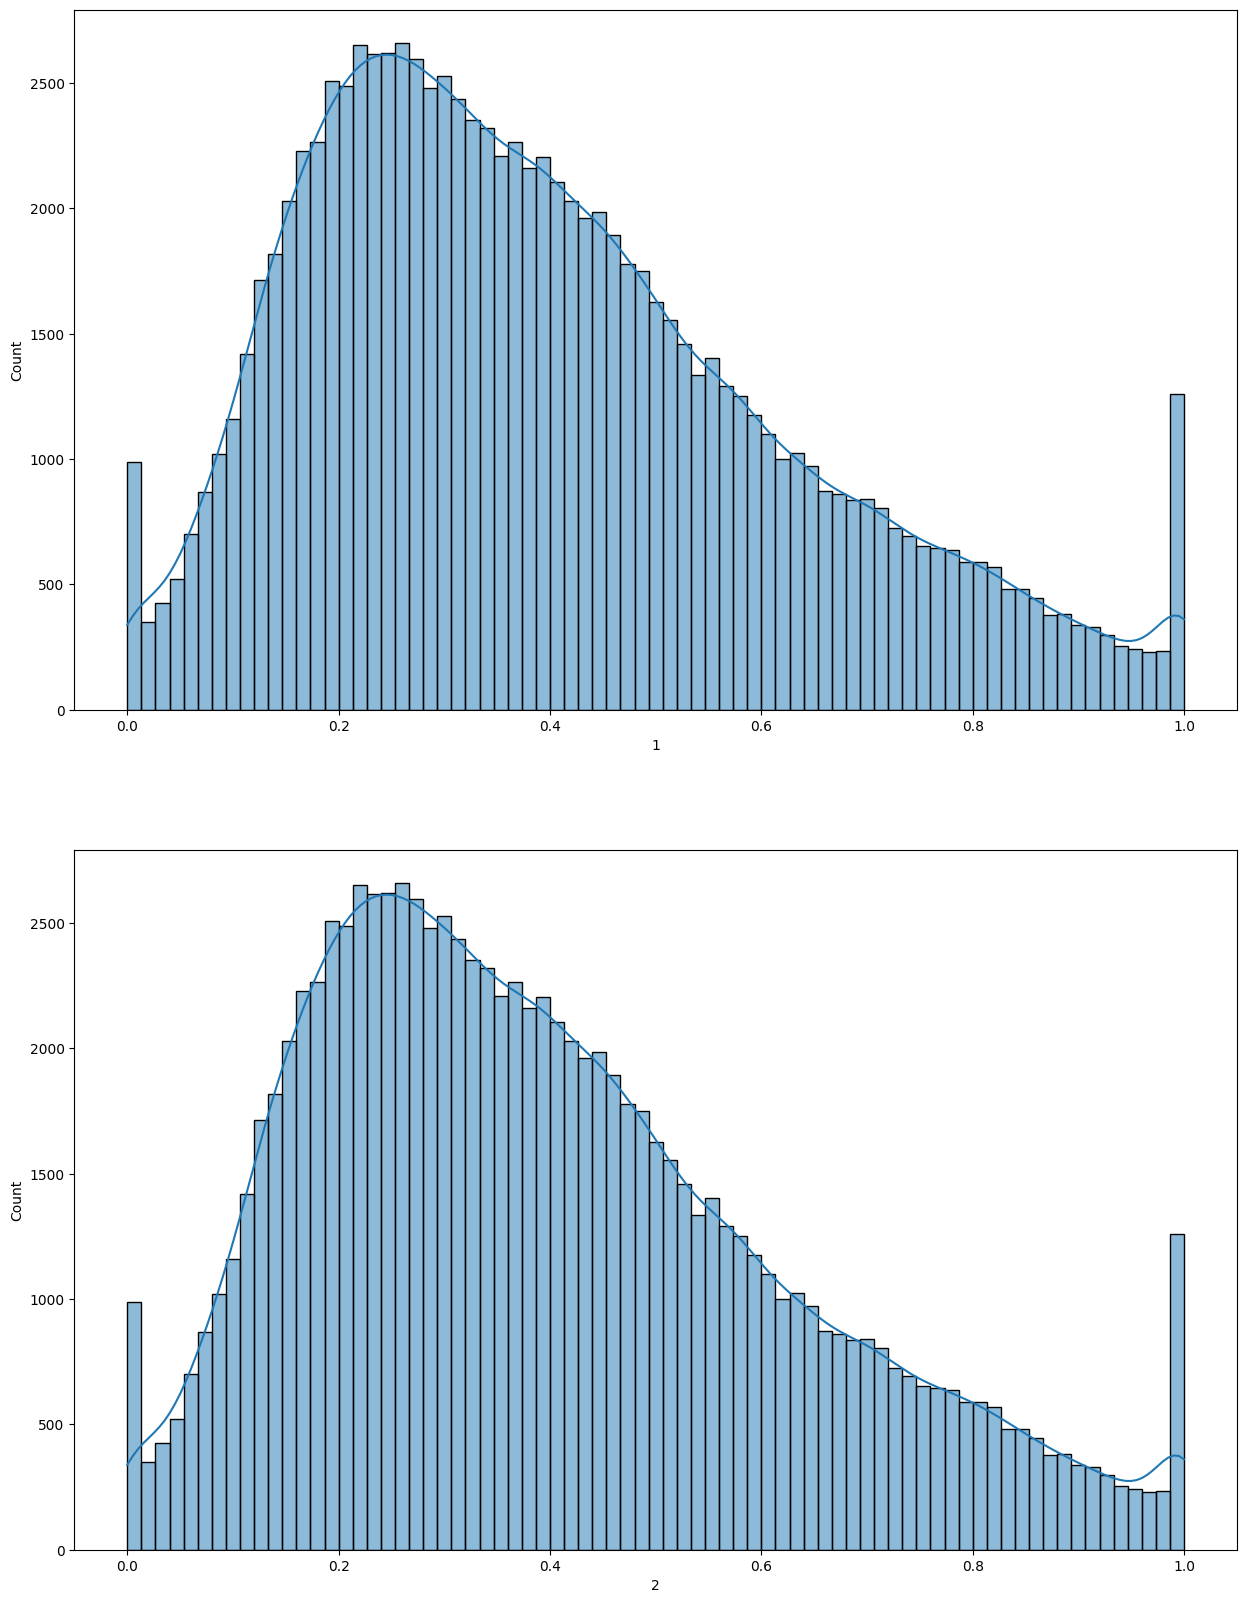

In [117]:
figure = plt.figure(figsize=(15, 20))
for i in range(1, 3):
    plt.subplot(2, 1, i)
    sns.histplot(Clean_data.iloc[:, i], kde=True)

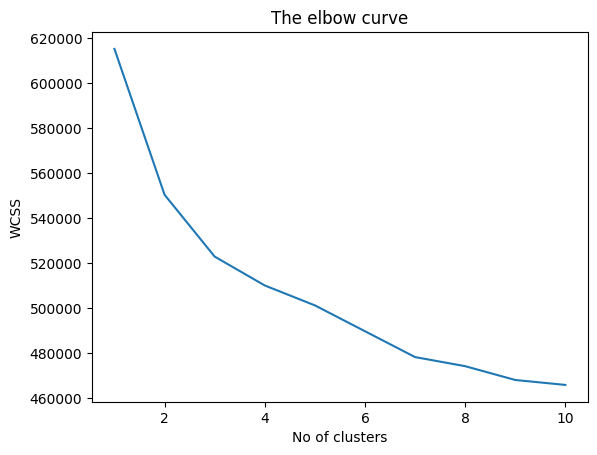

In [121]:
wcss = []
for i in range(1, 11):
    kmeans=KMeans(n_clusters=i, random_state=42)
    kmeans.fit(Clean_data)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss)
plt.title("The elbow curve")
plt.xlabel("No of clusters")
plt.ylabel("WCSS")
plt.show()

In [122]:
final_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
final_kmeans.fit(Clean_data)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [123]:
clusters = final_kmeans.predict(Clean_data)

In [124]:
dataset["Clusters"] = clusters

In [125]:
dataset.head()

,customer_id,age,gender,city,annual_income,monthly_income,membership_type,tenure_months,total_orders,purchase_frequency_monthly,...,loyalty_points,loyalty_status,email_open_rate,ad_click_rate,payment_method,device_type,marketing_channel,review_rating,cluster_label_hint,Clusters
0,SEG000001,26,Male,Nagpur,441099.0,36758.25,Gold,11,33,3.08,...,431,Low,0.29,0.21,Net Banking,Desktop,Offline,3.2,Budget Conscious,1
1,SEG000002,51,Male,Chennai,469034.0,39086.17,Gold,44,47,1.27,...,528,Low,0.18,0.14,UPI,Mobile,Email,2.8,At Risk,1
2,SEG000003,30,Male,Mumbai,1056803.0,88066.92,Silver,49,361,7.37,...,6600,High,0.75,0.17,Net Banking,Tablet,Organic Search,3.7,Loyal Regular,0
3,SEG000004,32,Female,Kolkata,397014.0,33084.50,Platinum,41,46,1.32,...,1005,Medium,0.43,0.07,Credit Card,Tablet,Referral,3.1,Occasional Buyer,2
4,SEG000005,54,Female,Bengaluru,639236.0,53269.67,Silver,63,686,10.86,...,20167,High,0.50,0.28,Net Banking,Mobile,Google Ads,4.1,High Value,0


In [130]:
dataset["Clusters"].value_counts()

Clusters
0    34860
1    34053
2    18792
3    12295
Name: count, dtype: int64

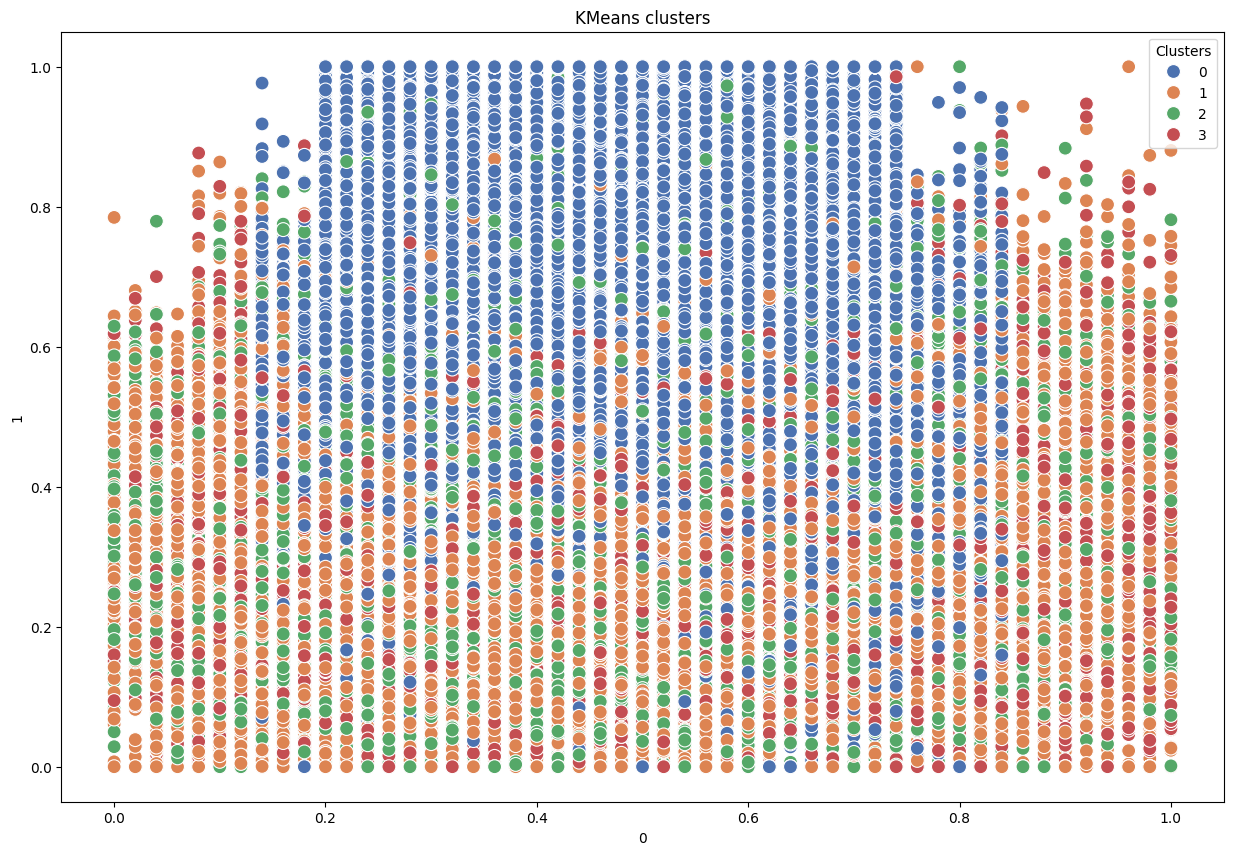

In [133]:
plt.figure(figsize=(15, 10))
sns.scatterplot(
    x = Clean_data.iloc[:, 0],
    y = Clean_data.iloc[:, 1],
    hue = clusters,
    palette = "deep",
    s=100
)

plt.title("KMeans clusters")
plt.xlabel(Clean_data.columns[0])
plt.ylabel(Clean_data.columns[1])
plt.legend(title="Clusters")
plt.show()

In [134]:
joblib.dump(final_kmeans, "kmeans_model.pkl")

['kmeans_model.pkl']

In [135]:
sample_customer = {
    "age": 35,
    "gender": "Female",
    "city": "Pune",
    "annual_income": 1200000,
    "monthly_income": 100000,
    "membership_type": "Gold",
    "tenure_months": 48,
    "total_orders": 180,
    "purchase_frequency_monthly": 7.5,
    "average_order_value": 3200,
    "total_spend": 520000,
    "discount_usage_rate": 0.12,
    "coupon_usage_count": 15,
    "website_visits_monthly": 40,
    "app_usage_hours_weekly": 9,
    "cart_abandonment_rate": 0.15,
    "days_since_last_purchase": 5,
    "preferred_category": "Electronics",
    "num_categories_purchased": 6,
    "return_rate": 0.05,
    "customer_support_calls": 1,
    "complaint_level": "Low",
    "loyalty_points": 5200,
    "loyalty_status": "High",
    "email_open_rate": 0.65,
    "ad_click_rate": 0.22,
    "payment_method": "Credit Card",
    "device_type": "Mobile",
    "marketing_channel": "Instagram",
    "review_rating": 4.6
}

In [142]:
sample_df = pd.DataFrame([sample_customer])

predicted_cluster = final_kmeans.predict(
    preprocess_pipeline.transform(sample_df)
)

print("Predicted Cluster:", predicted_cluster[0])

Predicted Cluster: 0
